# Heavy/light Xonium cell: parametric sweeps

Sweeps of `parametric_CZ.ipynb` for the heavy/light fluxonium pair of `2Q.ipynb`, at half flux and with the couplings
of the ZZ-free region found there ($g_L$ = 84.9 MHz, $g_C$ = 400 MHz). Qubit A is the light fluxonium (driven and
flux-modulated in the sweeps), qubit B the heavy one. All quantities are in GHz with $\hbar = 1$ unless otherwise specified.

In [1]:
using ProjectRoot
using Pkg
const ROOT = @projectroot 
Pkg.activate(ROOT)

using Revise
using QuantumToolbox
using XoniumUnitCell
using ProgressMeter
using CairoMakie

  Activating 

project at `~/Projects/xonium/XoniumUnitCell.jl`


In [2]:
using LinearAlgebra

# run_spectography_flux_sweep_2a/run_cz_flux_sweep_2b parallelize their grid sweeps across Julia
# threads (see those functions' docstrings). Pin BLAS to 1 thread so the
# linear algebra inside each sesolve call doesn't spawn its own threads and
# oversubscribe the cores Julia's own threads are already using.
LinearAlgebra.BLAS.set_num_threads(1)

println("Threads.nthreads() = ", Threads.nthreads())
Threads.nthreads() == 1 && @warn "Only 1 thread available -- the sweep parallelism below will have no effect. Restart the kernel with more threads (VS Code: set \"julia.NumThreads\" to \"auto\" in settings, or set the JULIA_NUM_THREADS env var) before re-running."

Threads.nthreads() = 14

false

## System parameters

In [3]:
# Heavy/light fluxonium pair of 2Q.ipynb at half flux (δϕ = π). Qubit A is the light fluxonium, B the heavy one
const fA_params = (EC = 2.0 * 2π, EL = 1.0 * 2π, EJ = 3.0 * 2π, δϕ = π, name = :fA)    # light, f01 = 2.04 GHz
const fB_params = (EC = 0.4 * 2π, EL = 1.0 * 2π, EJ = 12.0 * 2π, δϕ = π, name = :fB)   # heavy, f01 = 0.09 MHz

# couplings in the ZZ-free region: -J φAφB + J_C nAnB, the signs of 2Q.ipynb's +g_L φφ - g_C nn flipped together
const J = 84.9 * 2π * 1e-3    # inductive coupling magnitude g_L
const J_C = 400.0 * 2π * 1e-3 # capacitive coupling g_C

# the linear-flux form needs ~80 oscillator states to converge for the heavy fluxonium (30 are not enough)
const H_kwargs = (J_C = J_C, qho_basis_nlev = 80, ebasis_nlev = 6)
const H_builder = first ∘ build_H_LC

first ∘ XoniumUnitCell.build_H_LC

In [4]:
# idle cell: dressed qubit frequencies and static ZZ at the sweet spot
sys_idle, _ = build_H_LC(fA_params, fB_params, J; H_kwargs...)
E = map(l -> real(energy(sys_idle, l; bare_to_dressed_tracking=:overlap)), (; gg=:gg, ge=:ge, eg=:eg, ee=:ee))
println("dressed f_A (light) = $(round((E.eg - E.gg) / 2π, digits=4)) GHz, f_B (heavy) = $(round(1e3 * (E.ge - E.gg) / 2π, digits=3)) MHz")
println("ζzz/2π = $(round(1e3 * static_ζ(fA_params, fB_params, 0.0, 0.0, J; H_builder=H_builder, H_builder_kwargs=H_kwargs) / 2π, digits=4)) MHz")

dressed f_A (light) = 2.1952 GHz, f_B (heavy) = 0.082 MHz


ζzz/2π = 0.0026 MHz


## Qubit-subspace couplings vs. flux detuning

In [5]:
# true detuning of both fluxonia from the sweet spot Φ0/2, as a flux angle 2πδΦ/Φ0 (total bias π + δϕ)
δϕs = collect(LinRange(-0.5, 0.5, 100))
0.0 ∈ δϕs || (δϕs = sort!([δϕs; 0.0]))  # always include the sweet spot

# the sweep forwards only the basis sizes to the builder, so J_C is bound in a closure
build_with_J_C = (pA, pB, J; kwargs...) -> build_H_LC(pA, pB, J; J_C=J_C, kwargs...)
sweep = sweep_couplings(δϕs, fA_params, fB_params, build_with_J_C, J; qho_basis_nlev=80, ebasis_nlev=6)

101-element StructArray(::Vector{ComplexF64}, ::Vector{ComplexF64}, ::Vector{ComplexF64}, ::Vector{ComplexF64}) with eltype @NamedTuple{xx::ComplexF64, xz::ComplexF64, zx::ComplexF64, zz::ComplexF64}:
 (xx = 9.76311893981293e-5 + 0.0im, xz = 2.091083369705391 + 0.0im, zx = -8.358185268292829e-5 + 0.0im, zz = -1.7901720058097152 + 0.0im)
 (xx = 9.675344364958204e-5 + 0.0im, xz = 2.100478774880524 + 0.0im, zx = -8.222392556687824e-5 + 0.0im, zz = -1.7850487168818177 + 0.0im)
 (xx = 9.598639698821641e-5 + 0.0im, xz = 2.1100289420622182 + 0.0im, zx = -8.095503738303443e-5 + 0.0im, zz = -1.779600831406366 + 0.0im)
 (xx = 9.532394127972175e-5 + 0.0im, xz = 2.119733945362901 + 0.0im, zx = -7.976838745823059e-5 + 0.0im, zz = -1.7738225716653429 + 0.0im)
 (xx = 9.476073521996879e-5 + 0.0im, xz = 2.1295937286923334 + 0.0im, zx = -7.865787296585359e-5 + 0.0im, zz = -1.7677080342561684 + 0.0im)
 (xx = 9.429211732812036e-5 + 0.0im, xz = 2.139608097277809 + 0.0im, zx = -7.761800120083595e-5 + 0.0im,

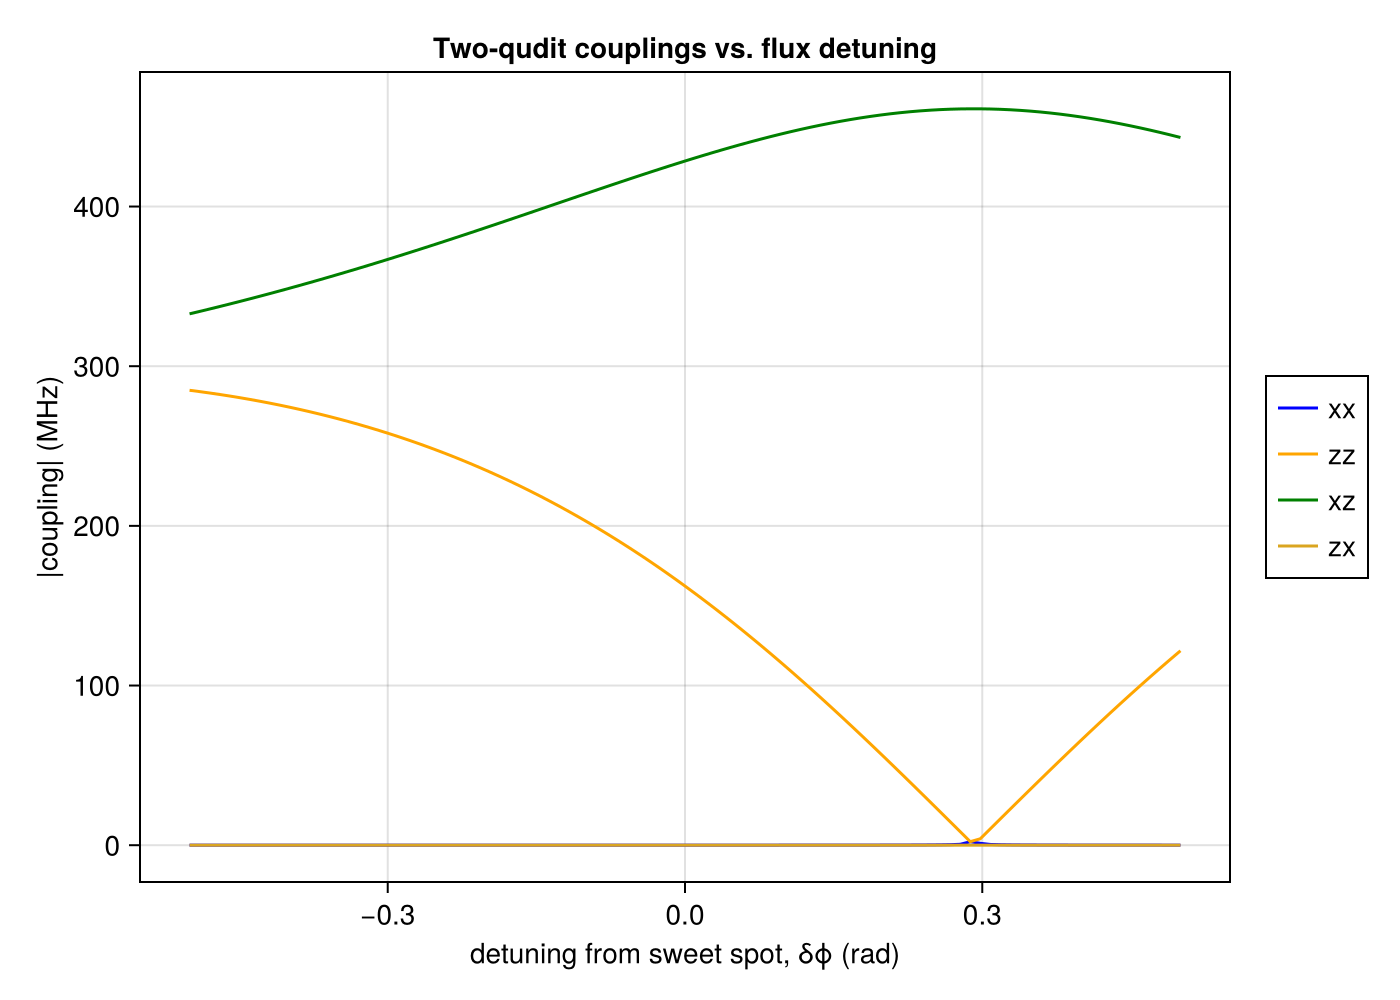

In [6]:
fig = Figure(size = (700, 500))
ax = Axis(
    fig[1, 1];
    xlabel = "detuning from sweet spot, δϕ (rad)",
    ylabel = "|coupling| (MHz)",
    title = "Two-qudit couplings vs. flux detuning",
    xgridvisible = true,
    ygridvisible = true,
)
component_colors = Dict(:xx => :blue, :zz => :orange, :xz => :green, :zx => :goldenrod)
foreach((:xx, :zz, :xz, :zx)) do component
    lines!(ax, δϕs, 1e3 .* abs.(getproperty(sweep, component)) ./ 2π; label = String(component), color = component_colors[component])
end
Legend(fig[1, 2], ax)
fig

## Spectroscopy of the light qubit vs. flux of the heavy qubit (Fig. 2a)

In [7]:
ωlist_2a = 2π .* LinRange(2.0, 2.4, 50)       # probe frequencies around the dressed light qubit, 2.195 GHz
δϕB_list_2a = LinRange(-0.6, 0.6, 50)         # flux detuning of the heavy qubit; its frequency crosses the light one near ±0.39

tlist = collect(LinRange(0, 200, 2))
t_ramp = 2.0
Ω_ge = 0.1

# drive envelope; the sweep multiplies it by cos(ωt) for every ω in ωlist_2a
env0 = cosine_ramp_envelope(t_ramp, maximum(tlist) - 2t_ramp)
env(p, t) = env0(t)

# `:overlap` keeps the state labels through the crossing of the two qubits, and the light qubit stays at its sweet spot (δϕA = 0)
P_transition = run_spectography_flux_sweep_2a(fA_params, fB_params, tlist, env, δϕB_list_2a, ωlist_2a, J, Ω_ge;
    δϕA=0.0, H_builder=H_builder, H_builder_kwargs=H_kwargs, state_tracking=:overlap)

Spectroscopy sweep:   0%|                 |  ETA: 1:29:52 ( 2.16  s/it)

Spectroscopy sweep:   4%|▊                |  ETA: 0:02:22 (59.39 ms/it)

Spectroscopy sweep:   4%|▊                |  ETA: 0:02:15 (56.33 ms/it)

Spectroscopy sweep:   5%|▊                |  ETA: 0:02:09 (53.99 ms/it)

Spectroscopy sweep:   5%|▉                |  ETA: 0:02:02 (51.32 ms/it)

...

Spectroscopy sweep:  99%|█████████████████|  ETA: 0:00:00 (17.35 ms/it)

Spectroscopy sweep:  99%|█████████████████|  ETA: 0:00:00 (17.38 ms/it)

Spectroscopy sweep:  99%|█████████████████|  ETA: 0:00:00 (17.45 ms/it)

Spectroscopy sweep: 100%|█████████████████| Time: 0:00:43 (17.50 ms/it)

50×50 Matrix{Float64}:
 0.000144335  0.000326829  2.41622e-5   …  0.000326829  0.000144335
 0.000363121  4.73155e-5   0.000326503     4.73154e-5   0.000363121
 7.08084e-5   0.000360029  0.000255455     0.000360028  7.08087e-5
 0.000418223  0.000310232  0.00010204      0.000310232  0.000418223
 0.000359391  0.000128686  0.000605932     0.000128686  0.000359391
 0.00017668   0.000701467  0.000104313  …  0.000701466  0.000176681
 0.00083237   0.000157467  0.000521416     0.000157467  0.00083237
 0.000204033  0.000622721  0.00074805      0.00062272   0.000204033
 0.000802862  0.000936881  9.16223e-5      0.000936881  0.000802862
 0.00117974   0.000147063  0.00144634      0.000147063  0.00117974
 0.000231064  0.00187959   0.000518797  …  0.00187959   0.000231065
 0.00262676   0.000737164  0.00106957      0.000737164  0.00262676
 0.00101108   0.00157844   0.00291423      0.00157844   0.00101108
 ⋮                                      ⋱               
 0.00252127   0.000370297  0.00196218    

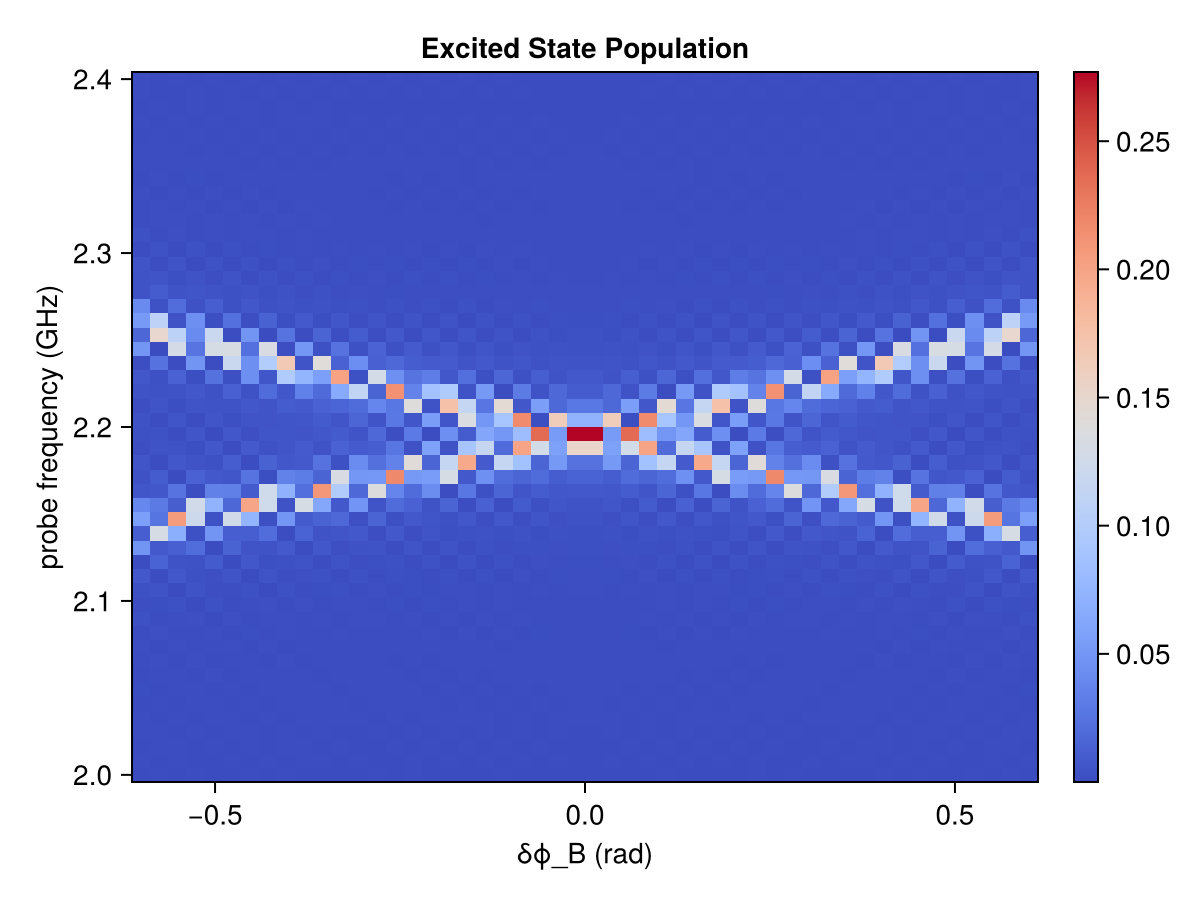

In [8]:
fig = Figure(size = (600, 450))
ax_a = Axis(fig[1, 1];
    xlabel = "δϕ_B (rad)",
    ylabel = "probe frequency (GHz)",
    title = "Excited State Population",
)
hm_a = heatmap!(ax_a, δϕB_list_2a, ωlist_2a ./ 2π, permutedims(P_transition); colormap = :coolwarm)
Colorbar(fig[1, 2], hm_a)
fig

## Conditional phase from flux pulses (Fig. 2b/c)

In [9]:
# dynamical CZ experiment: square flux pulses with tanh ramps on both qubits. The flux of the light qubit moves ζzz by
# ~2.4 GHz per rad, so a few 10⁻² rad suffice
δϕA_list_2b = LinRange(-0.03, 0.03, 21)
δϕB_list_2b = LinRange(-0.03, 0.03, 21)
vϕ_mtrx, err_mtrx, branch_mtrx, leak_mtrx = run_cz_flux_sweep_2b(fA_params, fB_params, δϕA_list_2b, δϕB_list_2b, J;
    τ=100.0, t_ramp=12.0, ramp_profile=:tanh, H_builder=H_builder, H_builder_kwargs=H_kwargs);

CZ flux sweep:   0%|▏                     |  ETA: 0:10:05 ( 1.38  s/it)

CZ flux sweep:   4%|█                     |  ETA: 0:01:11 ( 0.17  s/it)

CZ flux sweep:   6%|█▍                    |  ETA: 0:00:51 ( 0.12  s/it)

CZ flux sweep:   7%|█▋                    |  ETA: 0:00:48 ( 0.12  s/it)

CZ flux sweep:   8%|█▉                    |  ETA: 0:00:42 ( 0.10  s/it)

...

CZ flux sweep:  88%|███████████████████▎  |  ETA: 0:00:02 (37.82 ms/it)

CZ flux sweep:  91%|████████████████████  |  ETA: 0:00:02 (37.65 ms/it)

CZ flux sweep:  98%|█████████████████████▌|  ETA: 0:00:00 (37.13 ms/it)

CZ flux sweep:  99%|█████████████████████▉|  ETA: 0:00:00 (37.32 ms/it)

CZ flux sweep: 100%|██████████████████████| Time: 0:00:16 (37.97 ms/it)


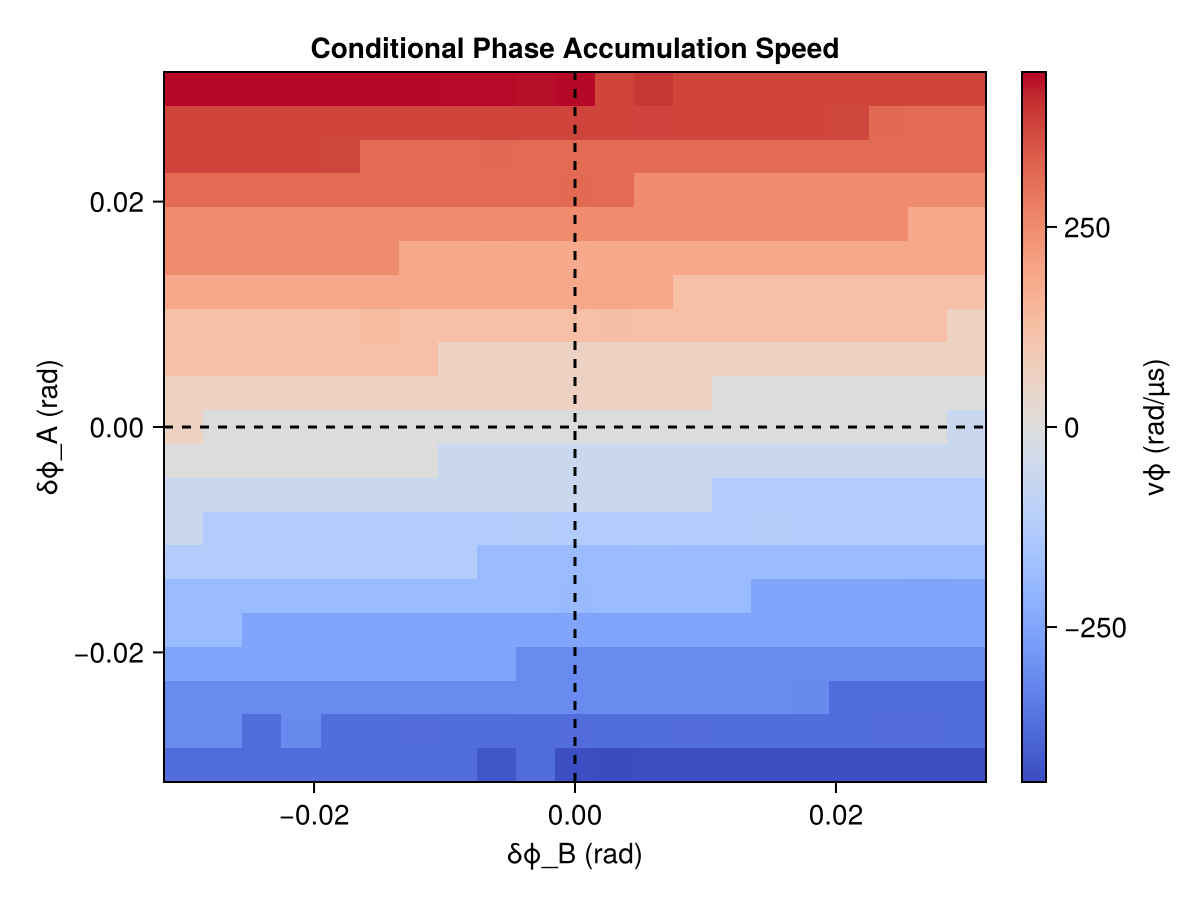

In [10]:
# conditional-phase accumulation speed, paper convention vϕ = 4 g_zz (blue < 0 < red)
fig = Figure(size = (600, 450))
ax_b = Axis(fig[1, 1];
    xlabel = "δϕ_B (rad)",
    ylabel = "δϕ_A (rad)",
    title = "Conditional Phase Accumulation Speed",
)
vmax = maximum(abs, vϕ_mtrx)
hm_b = heatmap!(ax_b, δϕB_list_2b, δϕA_list_2b, permutedims(vϕ_mtrx);
    colormap = :coolwarm, colorrange = (-vmax, vmax))
hlines!(ax_b, [0.0]; color = :black, linestyle = :dash)
vlines!(ax_b, [0.0]; color = :black, linestyle = :dash)
Colorbar(fig[1, 2], hm_b; label = "vϕ (rad/µs)")
fig

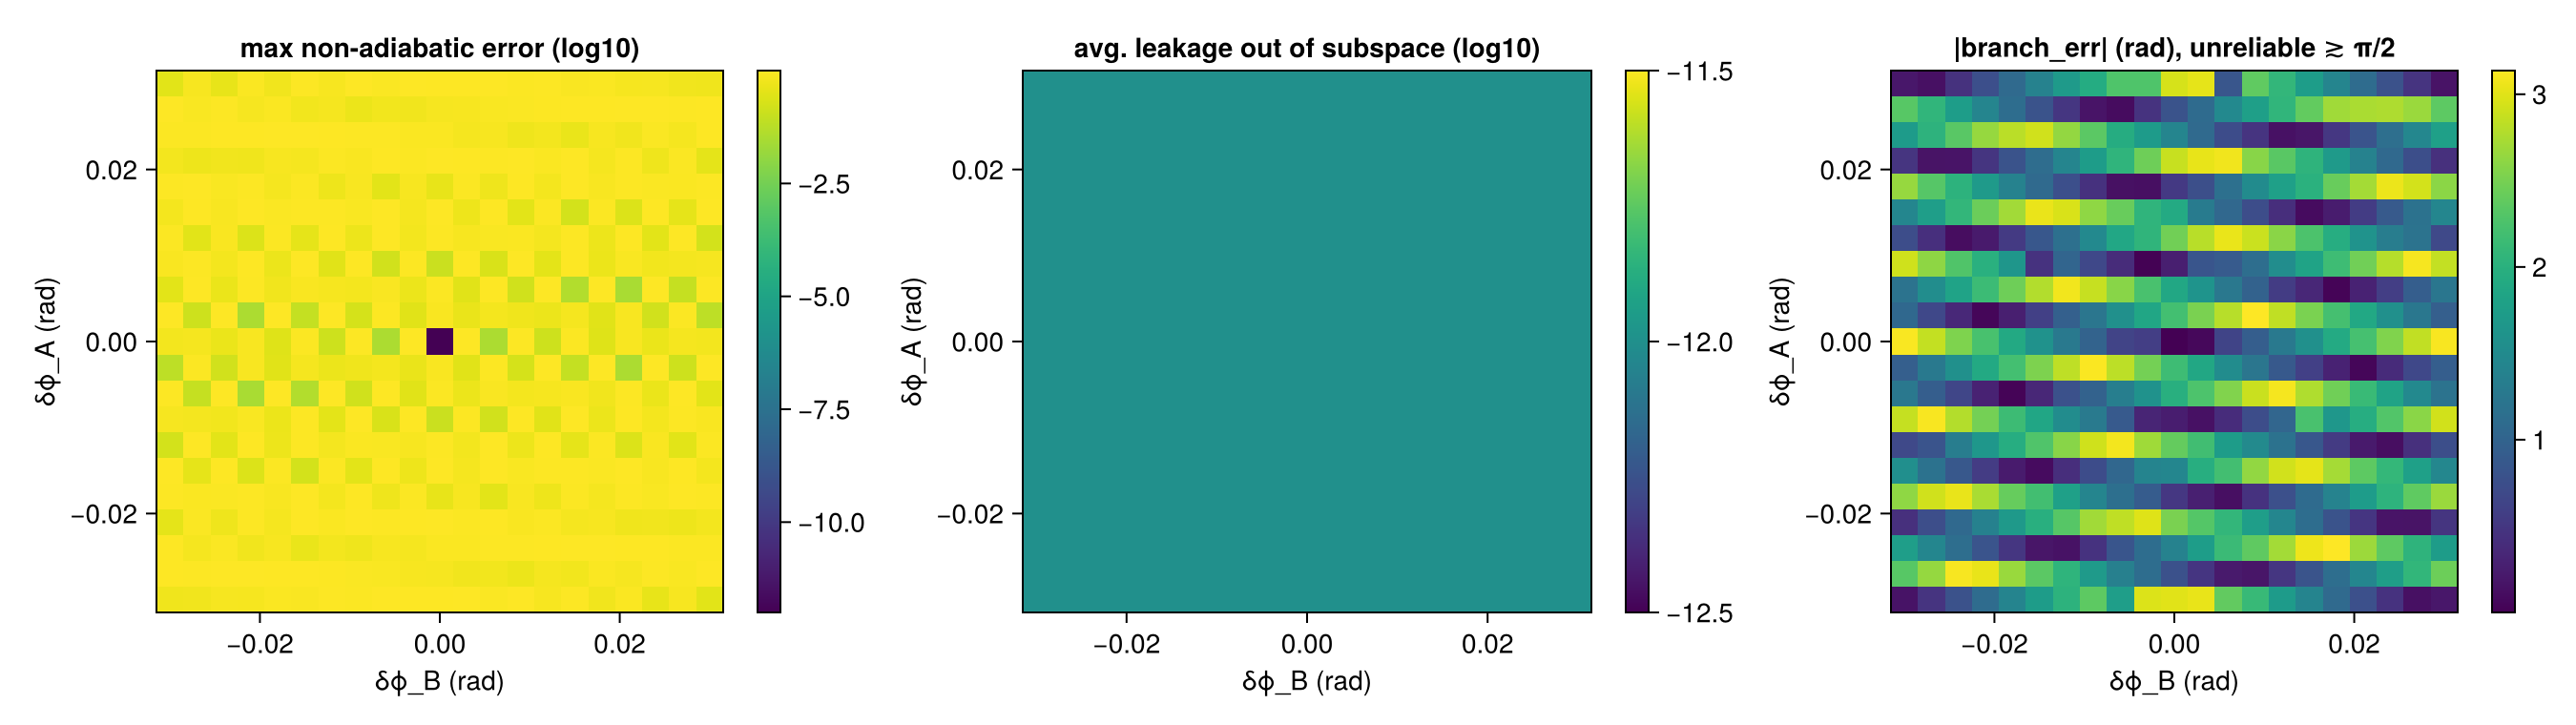

In [11]:
# diagnostics for the CZ sweep: non-adiabatic error, leakage, and 2π-branch confidence
fig_diag = Figure(size = (1350, 380))
ax_e = Axis(fig_diag[1, 1]; xlabel = "δϕ_B (rad)", ylabel = "δϕ_A (rad)", title = "max non-adiabatic error (log10)")
hm_e = heatmap!(ax_e, δϕB_list_2b, δϕA_list_2b, permutedims(log10.(max.(err_mtrx, 1e-12))); colormap = :viridis)
Colorbar(fig_diag[1, 2], hm_e)
ax_l = Axis(fig_diag[1, 3]; xlabel = "δϕ_B (rad)", ylabel = "δϕ_A (rad)", title = "avg. leakage out of subspace (log10)")
hm_l = heatmap!(ax_l, δϕB_list_2b, δϕA_list_2b, permutedims(log10.(max.(leak_mtrx, 1e-12))); colormap = :viridis)
Colorbar(fig_diag[1, 4], hm_l)
ax_r = Axis(fig_diag[1, 5]; xlabel = "δϕ_B (rad)", ylabel = "δϕ_A (rad)", title = "|branch_err| (rad), unreliable ≳ π/2")
hm_r = heatmap!(ax_r, δϕB_list_2b, δϕA_list_2b, permutedims(abs.(branch_mtrx)); colormap = :viridis)
Colorbar(fig_diag[1, 6], hm_r)
fig_diag

## Flux modulation of the light qubit and estimated dephasing (Fig. 3)

In [12]:
nθ = 400        # dense samples of the drive phase θ = ωt over one period (multiple of 4 and of nT_check)
nT_check = 20   # Floquet sample times for the consistency check
δλ_check = 0.5  # δλ for the tracked FloquetBasis of the consistency check

ωlist = 2π*1e-3 .* (50, 5, 0.5) # drive frequencies
Φlist = LinRange(0.0, 0.02, 10) # modulation amplitudes of the light qubit's flux, in Φ0

# Instantaneous eigenstates: for drives far slower than the qubit frequencies the Floquet states follow the
# eigenstates of H(δ) = H_idle + δ ΦA_op (see `flux_drive_operators`), with δ(t) = 2πΦ cos(ωt) on qubit A.
fig3 = run_flux_modulation_sweep(fA_params, fB_params, Φlist, J; δϕ_offsets=(0.0, 0.0), nθ=nθ,
                                 H_builder=H_builder, H_builder_kwargs=H_kwargs)
φt_sweep = fig3.φt_sweep   # ⟨φA⟩(θ) of (gg, ge, eg, ee) at each Φ
# same value for every drive frequency in the adiabatic limit
∂ωs = ones(length(ωlist)) * fig3.∂0'
∂λ_1 = ones(length(ωlist)) * fig3.∂1' # first-harmonic amplitude, same combination as ∂ωs

# Consistency check against tracked Floquet states at the largest drive amplitude and the fastest drive
chk = floquet_instantaneous_check(fig3.sys, J, maximum(ωlist), maximum(Φlist); nθ=nθ, nT=nT_check, δλ=δλ_check)
println("Consistency check at ω/2π = $(round(1e3 * maximum(ωlist) / 2π, sigdigits=3)) MHz, Φ = $(maximum(Φlist)) Φ0, δλ = $δλ_check:")
for lbl in keys(chk.min_overlap)
    println("  $lbl: min |⟨inst|Floquet⟩|² = $(round(chk.min_overlap[lbl], digits=5)), ",
            "max |Δ⟨φA⟩| = $(round(chk.max_Δφ[lbl], sigdigits=3))")
end
println("  ∂ωs:  Floquet $(round(chk.Floquet.∂0, sigdigits=4)), instantaneous $(round(chk.instantaneous.∂0, sigdigits=4))")
println("  ∂λ_1: Floquet $(round(chk.Floquet.∂1, sigdigits=4)), instantaneous $(round(chk.instantaneous.∂1, sigdigits=4))",
        " (both from the $nT_check check samples)")

Flux modulation sweep:  20%|██▊           |  ETA: 0:00:03 ( 0.34  s/it)

Flux modulation sweep: 100%|██████████████| Time: 0:00:00 (82.16 ms/it)


Consistency check at ω/2π = 50.0 MHz, Φ = 0.02 Φ0, δλ = 0.5:


  gg: min |⟨inst|Floquet⟩|² = 0.02964, max |Δ⟨φA⟩| = 0.804
  ge: min |⟨inst|Floquet⟩|² = 0.02964, max |Δ⟨φA⟩| = 0.804
  eg: min |⟨inst|Floquet⟩|² = 0.01073, max |Δ⟨φA⟩| = 0.428
  ee: min |⟨inst|Floquet⟩|² = 0.01073, max |Δ⟨φA⟩| = 0.428
  ∂ωs:  Floquet 5.391e-5, instantaneous 1.183e-6
  ∂λ_1: Floquet 0.5343, instantaneous 0.534 (both from the 20 check samples)


In [13]:
# Estimated dephasing rate Γφ of the light qubit from the environmental noise PSD (src/env_psd.jl), default kT of 1.5 mK
S_noise = qubit_pink_noise(fA_params; qho_basis_nlev=80)
Γφ = dephasing_rates(φt_sweep, ωlist, S_noise)   # rate in 1/ns, indexed [ω, Φ]

3×10 Matrix{Float64}:
 1.01564e-9  5.77374e-9  6.4039e-9   …  6.92084e-9  7.0249e-9   7.14024e-9
 1.01564e-9  2.89334e-9  3.02408e-9     4.87764e-9  5.48965e-9  6.18006e-9
 1.01564e-9  2.81291e-8  2.93714e-8     4.77896e-8  5.38774e-8  6.07453e-8

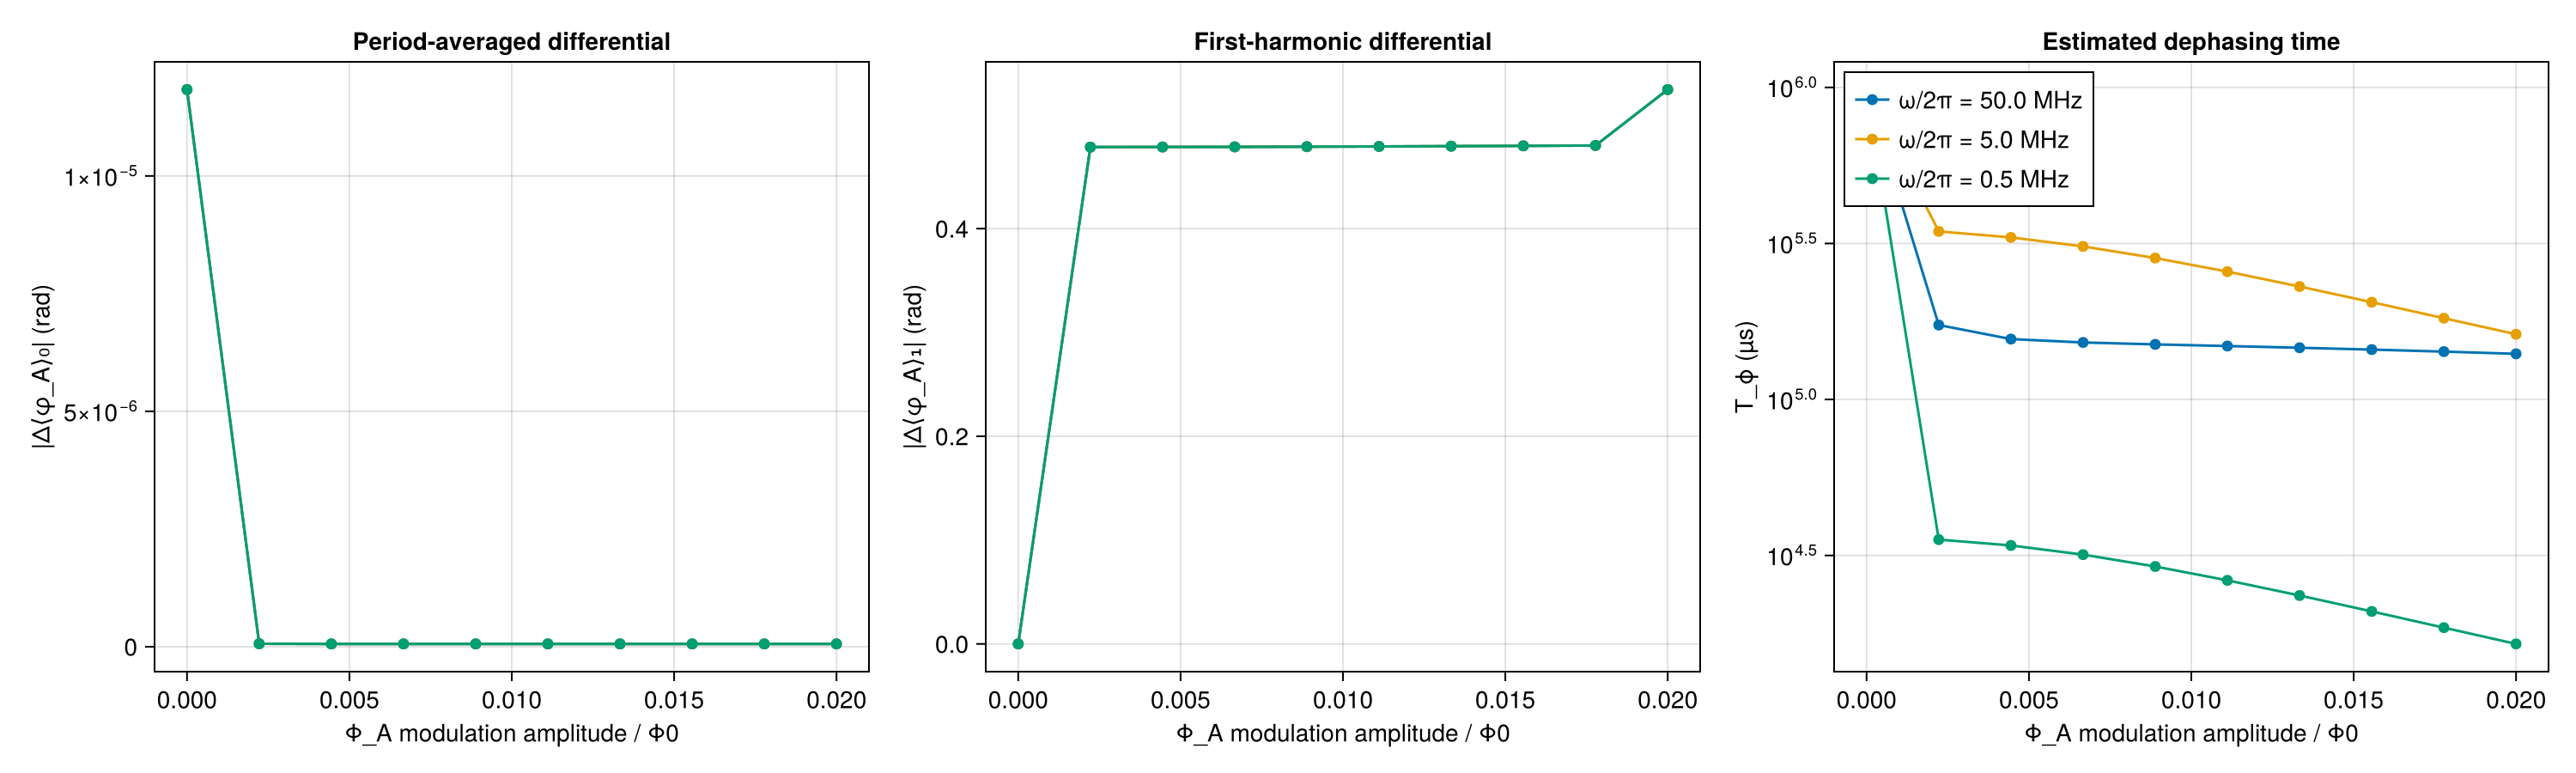

In [14]:
# plot the period-averaged (∂ωs) and first-harmonic (∂λ_1) differentials side by side,
# one curve per drive frequency
fig_dd = Figure(size = (1500, 450))

ax_0 = Axis(fig_dd[1, 1];
    xlabel = "Φ_A modulation amplitude / Φ0",
    ylabel = "|Δ⟨φ_A⟩₀| (rad)",
    title = "Period-averaged differential",
)
ax_1 = Axis(fig_dd[1, 2];
    xlabel = "Φ_A modulation amplitude / Φ0",
    ylabel = "|Δ⟨φ_A⟩₁| (rad)",
    title = "First-harmonic differential",
)
ax_2 = Axis(fig_dd[1, 3];
    xlabel = "Φ_A modulation amplitude / Φ0",
    ylabel = "T_ϕ (µs)",
    title = "Estimated dephasing time",
    yscale = log10,
)
for (i, ω) in enumerate(ωlist)
    lbl = "ω/2π = $(round(1e3 * ω / 2π, sigdigits=3)) MHz"
    scatterlines!(ax_0, Φlist, ∂ωs[i, :]; label = lbl)
    scatterlines!(ax_1, Φlist, ∂λ_1[i, :]; label = lbl)
    scatterlines!(ax_2, Φlist, 1e-3 .* (Γφ[i, :].^-1); label = lbl)   # 1/ns → 1/µs
end
axislegend(ax_2; position = :lt)

fig_dd